# Experiment 1: Vector and Matrix Operations for Deep Learning

An online bookstore represents six customers by five genre ratings and four books by genre weights. The recommendation team needs customer–book scores, customer similarity and a manual dense-layer calculation. The matrices and numeric values below are generated afresh for this notebook.

**Tools:** NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Build the 6×5 customer–genre and 5×4 genre–book matrices.  2. Compute dot products, matrix product, transpose, a valid regularised inverse and element-wise operations.  3. Find the most similar pair of distinct customers by cosine similarity.  4. Manually calculate y = Wx + b for one customer.  5. Plot the score matrix as a heatmap.

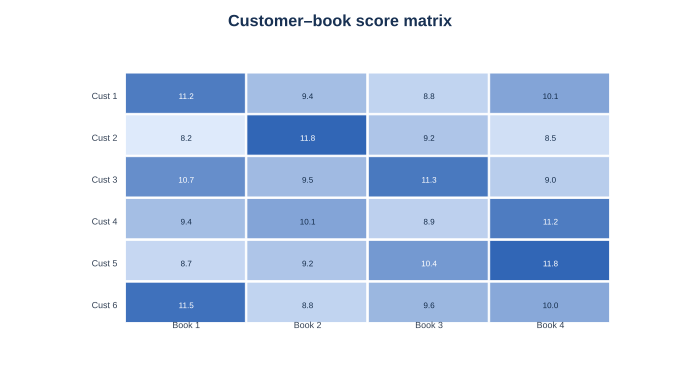

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(47)
customer_genre = rng.integers(1, 6, size=(6, 5)).astype(float)
genre_book = rng.uniform(0.05, 1.0, size=(5, 4))
print("Customer–genre ratings (6×5):\n", customer_genre)
print("\nGenre–book weights (5×4):\n", np.round(genre_book, 2))

# Dot products, matrix product, transpose, and element-wise scaling.
customer_0_dot = np.dot(customer_genre[0], genre_book[:, 0])
scores = customer_genre @ genre_book
print("\nCustomer 0 · Book 0:", round(customer_0_dot, 3))
print("\nCustomer–book scores (6×4):\n", np.round(scores, 2))
print("\nTranspose of customer–genre (5×6):\n", customer_genre.T)
scaled_scores = scores * 0.1
print("\nScores scaled element-wise by 0.1:\n", np.round(scaled_scores, 2))

# A rectangular matrix has no ordinary inverse. The regularised Gram matrix is square and invertible.
gram = customer_genre.T @ customer_genre + 0.1 * np.eye(5)
print("\nRegularised Gram-matrix inverse (5×5):\n", np.round(np.linalg.inv(gram), 3))

# Cosine similarity; inspect only the upper triangle to avoid duplicate pairs.
norms = np.linalg.norm(customer_genre, axis=1, keepdims=True)
similarity = (customer_genre @ customer_genre.T) / (norms @ norms.T)
pairs = np.triu_indices(6, k=1)
best = np.argmax(similarity[pairs])
i, j = pairs[0][best], pairs[1][best]
print(f"\nMost similar distinct customers: {i} and {j} (cosine={similarity[i, j]:.4f})")

# Dense layer for Customer 0: W is the transposed genre–book matrix.
x = customer_genre[0]
W = genre_book.T
b = np.array([0.2, -0.1, 0.0, 0.15])
y = W @ x + b
print("\nManual dense layer y = Wx + b:", np.round(y, 3))

plt.figure(figsize=(7, 4.5))
plt.imshow(scores, cmap="viridis", aspect="auto")
plt.colorbar(label="Recommendation score")
plt.xticks(range(4), [f"Book {k+1}" for k in range(4)])
plt.yticks(range(6), [f"Customer {k+1}" for k in range(6)])
plt.xlabel("Book"); plt.ylabel("Customer")
plt.title("Customer–book score matrix")
plt.tight_layout(); plt.show()